# 🦜🕸️ LangGraph: Basic to Advanced (with Ollama, 100% local)

This notebook teaches **LangGraph** step by step. Every LLM call runs on your machine through **Ollama**, so you don't need an API key.

**How to use it:** run the cells top to bottom. Each part builds on earlier ones, and every section starts with a short explanation followed by runnable code. Small local models sometimes act a little unpredictably. If a tool call or a route looks odd, run the cell again or switch to a stronger model in the config cell.

## 📚 Table of Contents

| # | Part | What you'll learn |
|---|------|-------------------|
| 0 | Setup | Install packages, pull Ollama models, sanity check |
| 1 | LLM basics with `ChatOllama` | invoke, messages, streaming, batch, prompts, LCEL chains |
| 2 | Your first graph (no LLM) | State, nodes, edges, `START`/`END`, compile, visualize |
| 3 | State deep-dive | Reducers, `add_messages`, input/output schemas |
| 4 | LLM chatbot graph | `MessagesState`, LLM as a node |
| 5 | Conditional edges and routing | LLM router with structured output |
| 6 | Structured output | Pydantic extraction with local models |
| 7 | Tools and tool calling | `@tool`, `bind_tools`, manual ReAct loop, `ToolNode`, `tools_condition` |
| 8 | Prebuilt agents | `create_agent` / `create_react_agent` |
| 9 | Short-term memory | Checkpointers, threads, state inspection, time travel and forking |
| 10 | Long conversations | Trimming and summarizing messages, `RemoveMessage` |
| 11 | Long-term memory | `Store` with cross-thread memory and semantic search |
| 12 | Streaming | `values`, `updates`, `messages` (tokens), `custom`, async |
| 13 | Human-in-the-loop | `interrupt()`, `Command(resume=...)`, approve/edit/reject, breakpoints |
| 14 | `Command` | Update state and route from inside a node |
| 15 | Parallelism and map-reduce | Fan-out/fan-in, the `Send` API |
| 16 | Subgraphs | Shared-state and different-state subgraphs |
| 17 | Multi-agent systems | Supervisor architecture |
| 18 | Agentic workflow patterns | Prompt chaining, evaluator-optimizer, plan-and-execute |
| 19 | RAG and agentic RAG | Ollama embeddings, retrieval graphs, grading, query rewriting |
| 20 | Functional API | `@entrypoint`, `@task` |
| 21 | Production features | Runtime context, retries, caching, recursion limits, fallbacks, persistent checkpointers |
| 22 | MCP integration | Use MCP server tools inside a LangGraph agent |
| 23 | Async and deployment | `ainvoke`, concurrency, `langgraph.json`, LangGraph Studio |
| 24 | Cheat sheet  | |

---
# Part 0 · Setup

### 0.1 Install Ollama and pull models
1. Download and install Ollama from **https://ollama.com/download**. On Windows, the installer adds `ollama` to PATH, so restart VS Code or your terminal afterwards.
2. In a terminal, pull a chat model that supports **tool calling** and an **embedding** model:

```bash
ollama pull llama3.1:8b        # chat + tool calling (~4.7 GB)
ollama pull nomic-embed-text   # embeddings for RAG / semantic memory
```

Other good tool-calling models are `qwen2.5:7b`, `qwen3:8b` and `mistral-nemo`. For a weak laptop, try `llama3.2:3b`; it is faster but makes more mistakes.

3. Ollama runs as a background service at `http://localhost:11434`. If it isn't running, start it with `ollama serve`.

### 0.2 Install Python packages

In [ ]:
%pip install -qU langgraph langchain langchain-core langchain-ollama langchain-mcp-adapters mcp pydantic langgraph-checkpoint-sqlite numpy

### 0.3 Global config and a sanity check
Change `MODEL` here and it applies to the whole notebook.

In [71]:
import operator
import uuid
from typing import Annotated, Literal, TypedDict

from pydantic import BaseModel, Field
from IPython.display import Image, display

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_core.messages import (
    AIMessage, HumanMessage, SystemMessage, ToolMessage, RemoveMessage,
)

MODEL = "llama3.1:8b"            # chat + tools model
EMBED_MODEL = "nomic-embed-text"  # embedding model
OLLAMA_URL = "http://localhost:11434"

# temperature=0 -> more deterministic, which helps routing and tool calling
llm = ChatOllama(model=MODEL, temperature=0, base_url=OLLAMA_URL)


def show_graph(graph, xray=False):
    """Render a compiled graph as a PNG. Falls back to Mermaid text when offline."""
    try:
        display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
    except Exception:
        print(graph.get_graph(xray=xray).draw_mermaid())


print(llm.invoke("Reply with exactly: Ollama is working!").content)

Ollama is working!


---
# Part 1 · LLM basics with `ChatOllama`

LangGraph doesn't care which LLM you use. It just calls Python functions. Still, you need to know the LangChain chat-model interface, because that's how most LangGraph apps talk to models. `ChatOllama` provides that interface:

| Method | Purpose |
|---|---|
| `.invoke(input)` | One call, returns an `AIMessage` |
| `.stream(input)` | Yields chunks token by token |
| `.batch([inputs])` | Many calls in parallel |
| `.bind_tools(tools)` | Lets the model request tool calls (Part 7) |
| `.with_structured_output(Schema)` | Forces output to match a Pydantic schema (Part 6) |

The input can be a string, a list of message objects, or a list of `{"role": ..., "content": ...}` dicts.

In [72]:
# 1.1 invoke with message objects
resp = llm.invoke([
    SystemMessage("You are a pirate. Answer in one sentence."),
    HumanMessage("What is LangGraph?"),
])
print(type(resp).__name__, "→", resp.content)
print("\nMetadata:", {k: resp.response_metadata.get(k) for k in ("model", "total_duration", "eval_count")})
print("Usage:", resp.usage_metadata)

AIMessage → LangGraph be a tool fer analyzing and visualizin' language patterns, like a treasure map fer linguists!

Metadata: {'model': 'llama3.1:8b', 'total_duration': 13189906800, 'eval_count': 23}
Usage: {'input_tokens': 30, 'output_tokens': 23, 'total_tokens': 53}


In [73]:
# 1.2 the same thing with dict-style messages (OpenAI format)
resp = llm.invoke([
    {"role": "system", "content": "You are a helpful teacher. Be brief."},
    {"role": "user", "content": "What is a directed graph?"},
])
print(resp.content)

A directed graph, also known as a digraph, is a type of graph where edges have direction. Each edge has a starting node (tail) and an ending node (head), indicating the flow of information or relationship between nodes.

Think of it like a one-way street: you can travel from A to B, but not from B to A.


In [74]:
# 1.3 streaming tokens
for chunk in llm.stream("Count from 1 to 10, separated by commas."):
    print(chunk.content, end="", flush=True)

1, 2, 3, 4, 5, 6, 7, 8, 9, 10.

In [75]:
# 1.4 batch: several prompts handled concurrently
answers = llm.batch(["Capital of France? One word.", "Capital of Japan? One word.", "2+2? Just the number."])
print([a.content for a in answers])

['Paris.', 'Tokyo.', '4']


In [76]:
# 1.5 prompt templates + LCEL chain (prompt | model | parser)
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You explain technical topics to a {audience}."),
    ("human", "Explain {topic} in 2 sentences."),
])
chain = prompt | llm | StrOutputParser()
print(chain.invoke({"audience": "10 year old", "topic": "a state machine"}))

So, imagine you're playing a game where you have to follow a set of rules, like "if you're in the kitchen, then you can't go to the living room". A state machine is like a special computer program that follows a set of rules like that, where it changes what it's doing based on what "state" it's in, like being in the kitchen or the living room.


> 💡 **Chains vs. graphs.** An LCEL chain is a straight pipeline. LangGraph adds **cycles, branching, shared state, persistence, human-in-the-loop and multi-agent coordination**. Use a chain for a simple fixed pipeline and LangGraph when you need control flow.

---
# Part 2 · Your first graph (no LLM yet)

A LangGraph app is a **state machine** with three parts:

1. **State**: a shared data structure, usually a `TypedDict`, that flows through the graph.
2. **Nodes**: plain Python functions `state -> partial update (dict)`.
3. **Edges**: which node runs next. `START` and `END` are special virtual nodes.

You **build** the graph with a `StateGraph`, then call `.compile()` to get a runnable that has `.invoke`, `.stream`, `.batch` and the async versions.

> 🔑 A node returns **only the keys it wants to change**. LangGraph merges that partial update into the state.

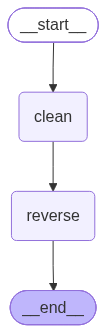

{'text': 'hparggnal olleh', 'log': ['clean', 'reverse']}

In [77]:
from langgraph.graph import StateGraph, START, END


class TextState(TypedDict):
    text: str
    log: list[str]


def clean(state: TextState) -> dict:
    return {"text": state["text"].strip().lower(), "log": state["log"] + ["clean"]}


def reverse(state: TextState) -> dict:
    return {"text": state["text"][::-1], "log": state["log"] + ["reverse"]}


builder = StateGraph(TextState)
builder.add_node("clean", clean)
builder.add_node("reverse", reverse)
builder.add_edge(START, "clean")
builder.add_edge("clean", "reverse")
builder.add_edge("reverse", END)

text_graph = builder.compile()
show_graph(text_graph)
text_graph.invoke({"text": "   Hello LangGraph   ", "log": []})

In [78]:
# Shortcut for linear pipelines: add_sequence (node names = function names)
builder = StateGraph(TextState)
builder.add_sequence([clean, reverse])
builder.add_edge(START, "clean")
print(builder.compile().invoke({"text": "  ABC  ", "log": []}))

{'text': 'cba', 'log': ['clean', 'reverse']}


---
# Part 3 · State deep-dive: reducers and schemas

### 3.1 Reducers
By default, a key a node returns **overwrites** the old value. A **reducer** changes that: it tells LangGraph how to *combine* the old and new values. You attach one with `Annotated[type, reducer_fn]`.

In [79]:
class LogState(TypedDict):
    text: str
    log: Annotated[list[str], operator.add]   # new items are APPENDED


def step_a(state: LogState):
    return {"log": ["A ran"]}          # no need to copy the old list


def step_b(state: LogState):
    return {"text": state["text"] + "!", "log": ["B ran"]}


b = StateGraph(LogState)
b.add_sequence([step_a, step_b])
b.add_edge(START, "step_a")
b.compile().invoke({"text": "hi", "log": ["start"]})

{'text': 'hi!', 'log': ['start', 'A ran', 'B ran']}

In [80]:
# A custom reducer: keep only the last 3 items
def keep_last_3(old: list, new: list) -> list:
    return (old + new)[-3:]


class WindowState(TypedDict):
    items: Annotated[list[int], keep_last_3]


def add_two(state: WindowState):
    return {"items": [len(state["items"]) * 10, len(state["items"]) * 10 + 1]}


b = StateGraph(WindowState)
b.add_node("n1", add_two)
b.add_node("n2", add_two)
b.add_edge(START, "n1")
b.add_edge("n1", "n2")
b.compile().invoke({"items": [1, 2]})

{'items': [21, 30, 31]}

### 3.2 `add_messages`, the chat reducer
For chat apps the state usually holds a list of messages, and the built-in `add_messages` reducer handles it:
- it **appends** new messages,
- it **replaces** a message that has the same `id` (handy for edits),
- it converts dicts and tuples into message objects.

`MessagesState` is a ready-made state with `messages: Annotated[list, add_messages]`.

In [81]:
from langgraph.graph.message import add_messages

msgs = add_messages([HumanMessage("hi", id="1")], [AIMessage("hello!", id="2")])
print([m.content for m in msgs])

msgs = add_messages(msgs, [HumanMessage("hi (edited)", id="1")])   # same id -> replaced
print([m.content for m in msgs])

msgs = add_messages(msgs, [{"role": "user", "content": "dicts work too"}])
print([(type(m).__name__, m.content) for m in msgs])

['hi', 'hello!']
['hi (edited)', 'hello!']
[('HumanMessage', 'hi (edited)'), ('AIMessage', 'hello!'), ('HumanMessage', 'dicts work too')]


### 3.3 Input / output / private schemas
A graph can accept a narrow **input**, return a narrow **output**, and keep internal keys hidden from callers.

In [82]:
class InputState(TypedDict):
    question: str

class OutputState(TypedDict):
    answer: str

class OverallState(InputState, OutputState):
    notes: str   # internal only


def think(state: InputState) -> dict:
    return {"notes": f"The user asked: {state['question']}. Answer in one sentence."}

def respond(state: OverallState) -> dict:
    return {"answer": llm.invoke(state["notes"]).content}


b = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
b.add_sequence([think, respond])
b.add_edge(START, "think")
qa_graph = b.compile()
qa_graph.invoke({"question": "Why is the sky blue?"})   # only {'answer': ...} comes back

{'answer': "The sky appears blue because of a phenomenon called Rayleigh scattering, where shorter (blue) wavelengths of light are scattered more than longer (red) wavelengths by the tiny molecules of gases in the Earth's atmosphere."}

> 📝 You can also use a **Pydantic model** or a **dataclass** as the state. Pydantic validates the input at runtime, at a small speed cost.

---
# Part 4 · An LLM chatbot graph

Now an LLM goes inside a node. The node reads the messages from state, calls the model and returns the new `AIMessage`. `add_messages` then appends it.

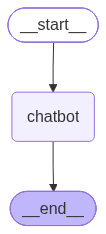

================================ Human Message =================================

Give me 3 real-world uses of graphs in CS.
================================== Ai Message ==================================

Here are 3 real-world uses of graphs in Computer Science:

1. **Social Network Analysis**: Graphs are used to model relationships between people, such as friendships, followers, or connections on social media platforms. This helps analyze and visualize the structure of social networks, identify influential users, and detect potential issues like spam or fake accounts.
2. **Traffic Routing and Navigation**: Graphs are used to represent road networks, allowing for efficient routing and navigation algorithms. This enables GPS systems to provide the shortest or fastest routes between two points, taking into account traffic patterns, road closures, and other factors.
3. **Recommendation Systems**: Graphs are used to model user preferences and item relationships in recommendation systems,

In [83]:
from langgraph.graph import MessagesState

CHAT_SYSTEM = SystemMessage("You are a concise, friendly assistant.")


def chatbot(state: MessagesState):
    return {"messages": [llm.invoke([CHAT_SYSTEM] + state["messages"])]}


b = StateGraph(MessagesState)
b.add_node("chatbot", chatbot)
b.add_edge(START, "chatbot")
b.add_edge("chatbot", END)
chat_graph = b.compile()

show_graph(chat_graph)
out = chat_graph.invoke({"messages": [HumanMessage("Give me 3 real-world uses of graphs in CS.")]})
for m in out["messages"]:
    m.pretty_print()

> ⚠️ This bot has **no memory between calls**. Each `invoke` starts fresh. Part 9 fixes that with checkpointers.

---
# Part 5 · Conditional edges and routing

`add_conditional_edges(source, routing_fn, path_map)` runs `routing_fn(state)` after `source` and goes to whichever node it returns. Here an LLM **router** classifies the question with structured output, and the graph sends it to a specialist node.

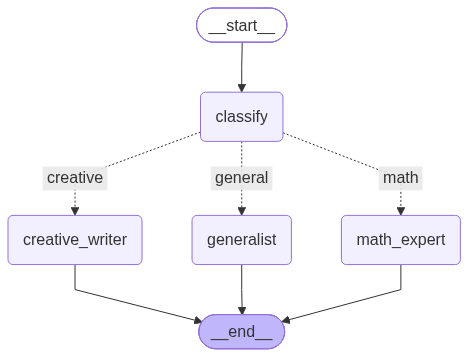

In [84]:
class Route(BaseModel):
    destination: Literal["math", "creative", "general"] = Field(
        description="math: calculations or math questions; creative: poems, stories, jokes; general: everything else"
    )


router_llm = llm.with_structured_output(Route)


class RouterState(TypedDict):
    question: str
    route: str
    answer: str


def classify(state: RouterState):
    decision = router_llm.invoke([
        SystemMessage("Classify the user's request into exactly one category."),
        HumanMessage(state["question"]),
    ])
    return {"route": decision.destination}


def math_expert(state: RouterState):
    return {"answer": llm.invoke(f"You are a math tutor. Solve step by step, briefly: {state['question']}").content}

def creative_writer(state: RouterState):
    return {"answer": llm.invoke(f"You are a playful creative writer. {state['question']}").content}

def generalist(state: RouterState):
    return {"answer": llm.invoke(f"Answer concisely: {state['question']}").content}


def pick_route(state: RouterState) -> Literal["math", "creative", "general"]:
    return state["route"]


b = StateGraph(RouterState)
b.add_node("classify", classify)
b.add_node("math_expert", math_expert)
b.add_node("creative_writer", creative_writer)
b.add_node("generalist", generalist)
b.add_edge(START, "classify")
b.add_conditional_edges(
    "classify",
    pick_route,
    {"math": "math_expert", "creative": "creative_writer", "general": "generalist"},
)
for n in ("math_expert", "creative_writer", "generalist"):
    b.add_edge(n, END)
router_graph = b.compile()
show_graph(router_graph)

In [85]:
for q in ["What is 17 * 23?", "Write a haiku about rain", "Who wrote Hamlet?"]:
    r = router_graph.invoke({"question": q})
    print(f"Q: {q}\n→ route: {r['route']}\n{r['answer']}\n" + "-" * 60)

Q: What is 17 * 23?
→ route: math
To solve this, I'll multiply the numbers:

1. Multiply 17 by 20: 17 * 20 = 340
2. Multiply 17 by 3: 17 * 3 = 51
3. Add the results: 340 + 51 = 391

The answer is: 391
------------------------------------------------------------
Q: Write a haiku about rain
→ route: creative
Droplets on my face
Rainy rhythm on the roof
Summer's sweet delight
------------------------------------------------------------
Q: Who wrote Hamlet?
→ route: general
William Shakespeare.
------------------------------------------------------------


---
# Part 6 · Structured output

`with_structured_output(PydanticModel)` makes the model return a validated object instead of free text. With Ollama, this uses its native JSON-schema mode (`format=`), which works well even with small models.

Common uses: **extraction**, **classification/routing**, **grading**, **planning**.

In [86]:
class Person(BaseModel):
    name: str
    age: int | None = Field(default=None, description="Age in years if mentioned")
    skills: list[str] = Field(default_factory=list)

class People(BaseModel):
    people: list[Person]


extractor = llm.with_structured_output(People)
text = ("Priya is a 29 year old data engineer who knows Python and Spark. "
        "Her colleague Tom, 35, works with Kubernetes, Go and Terraform.")
result = extractor.invoke(f"Extract all people from this text:\n{text}")
for p in result.people:
    print(p)

name='Priya' age=29 skills=[]
name='Tom' age=35 skills=[]


In [87]:
# include_raw=True also returns the raw AIMessage and any parsing error, which helps debugging
raw = llm.with_structured_output(Person, include_raw=True).invoke("Sam is 41 and loves cooking.")
print("parsed:", raw["parsed"])
print("error :", raw["parsing_error"])

parsed: name='Sam' age=41 skills=['cooking']
error : None


In [88]:
# Structured output inside a graph: an extraction node
class TicketState(TypedDict):
    email: str
    ticket: dict

class Ticket(BaseModel):
    category: Literal["billing", "bug", "feature_request", "other"]
    urgency: Literal["low", "medium", "high"]
    summary: str = Field(description="One-sentence summary")

def triage(state: TicketState):
    t = llm.with_structured_output(Ticket).invoke(f"Triage this support email:\n{state['email']}")
    return {"ticket": t.model_dump()}

b = StateGraph(TicketState)
b.add_node("triage", triage)
b.add_edge(START, "triage")
b.compile().invoke({"email": "Your app crashes every time I click export! I have a client demo in 1 hour!!"})

{'email': 'Your app crashes every time I click export! I have a client demo in 1 hour!!',
 'ticket': {'category': 'bug',
  'urgency': 'high',
  'summary': 'App crashes on export, client demo in 1 hour'}}

---
# Part 7 · Tools and tool calling

**Tool calling** is how an LLM *acts*. The model doesn't run anything itself. It returns a *request* (`tool_calls`), your code runs the tool, and you send the result back as a `ToolMessage`. Then the model continues.

```
User ─▶ LLM ─(tool_calls?)─ yes ─▶ run tools ─▶ ToolMessages ─▶ LLM ─▶ ...
                          └ no ─▶ final answer
```
This loop is the **ReAct agent**, and it's the most important pattern in LangGraph.

In [89]:
from langchain_core.tools import tool


@tool
def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b


@tool
def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b


@tool
def get_weather(city: str) -> str:
    """Get the current weather for a city."""
    fake_db = {"paris": "18°C, cloudy", "tokyo": "24°C, sunny", "london": "12°C, rain", "delhi": "33°C, hazy"}
    return fake_db.get(city.lower(), f"No weather data for {city}")


tools = [add, multiply, get_weather]
tools_by_name = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)

print(get_weather.name, "|", get_weather.description)
print(get_weather.args)   # JSON schema the LLM sees

get_weather | Get the current weather for a city.
{'city': {'title': 'City', 'type': 'string'}}


In [90]:
# 7.1 What does a tool call look like?
ai_msg = llm_with_tools.invoke("What is 12.5 multiplied by 4?")
print("content   :", repr(ai_msg.content))
print("tool_calls:", ai_msg.tool_calls)

content   : ''
tool_calls: [{'name': 'multiply', 'args': {'b': 4, 'a': 12.5}, 'id': '062b8bf7-df5f-45ef-90b7-c7807a8cb540', 'type': 'tool_call'}]


In [91]:
# 7.2 The ReAct loop by hand (no graph), to see the mechanics
messages = [HumanMessage("What's the weather in Paris, and what is 3 * 7?")]
ai_msg = llm_with_tools.invoke(messages)
messages.append(ai_msg)

for tc in ai_msg.tool_calls:
    result = tools_by_name[tc["name"]].invoke(tc["args"])
    print(f"🔧 {tc['name']}({tc['args']}) -> {result}")
    messages.append(ToolMessage(content=str(result), tool_call_id=tc["id"]))

print("\nFinal:", llm_with_tools.invoke(messages).content)

🔧 get_weather({'city': 'Paris'}) -> 18°C, cloudy
🔧 multiply({'a': '3', 'b': '7'}) -> 21.0

Final: The weather in Paris is 18°C, cloudy. The result of 3 * 7 is 21.0.


### 7.3 The ReAct agent as a graph (built from scratch)
Two nodes and a loop:
- `agent`: calls the LLM with tools bound
- `tools`: runs any requested tool calls
- a conditional edge: if the last AI message has `tool_calls`, go to `tools`, otherwise `END`
- `tools → agent` closes the loop

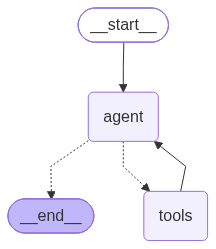

================================ Human Message =================================

Add 15 and 27, then multiply the result by 3.
================================== Ai Message ==================================
Tool Calls:
  multiply (0c7463cf-404f-46d6-bf87-11f07dc4cb8b)
 Call ID: 0c7463cf-404f-46d6-bf87-11f07dc4cb8b
  Args:
    a: 42
    b: 3
================================= Tool Message =================================
Name: multiply

126.0
================================== Ai Message ==================================

First, we add 15 and 27, which gives us 42. Then, we multiply 42 by 3, which gives us 126.


In [92]:
AGENT_SYSTEM = SystemMessage(
    "You are a helpful assistant. Use tools when they help. "
    "When you have the answer, reply to the user without calling tools."
)


def agent_node(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([AGENT_SYSTEM] + state["messages"])]}


def tool_node(state: MessagesState):
    outputs = []
    for tc in state["messages"][-1].tool_calls:
        try:
            result = tools_by_name[tc["name"]].invoke(tc["args"])
        except Exception as e:                       # feed errors back so the LLM can recover
            result = f"Error: {e}"
        outputs.append(ToolMessage(content=str(result), tool_call_id=tc["id"], name=tc["name"]))
    return {"messages": outputs}


def should_continue(state: MessagesState) -> Literal["tools", "__end__"]:
    return "tools" if state["messages"][-1].tool_calls else END


b = StateGraph(MessagesState)
b.add_node("agent", agent_node)
b.add_node("tools", tool_node)
b.add_edge(START, "agent")
b.add_conditional_edges("agent", should_continue)
b.add_edge("tools", "agent")
manual_agent = b.compile()
show_graph(manual_agent)

out = manual_agent.invoke({"messages": [HumanMessage("Add 15 and 27, then multiply the result by 3.")]})
for m in out["messages"]:
    m.pretty_print()

### 7.4 The same agent with prebuilt `ToolNode` + `tools_condition`
LangGraph ships both pieces. `ToolNode` runs tool calls **in parallel** and catches errors (`handle_tool_errors=True`). `tools_condition` is the same routing function as above.

In [93]:
from langgraph.prebuilt import ToolNode, tools_condition

react_builder = StateGraph(MessagesState)
react_builder.add_node("agent", agent_node)
react_builder.add_node("tools", ToolNode(tools))
react_builder.add_edge(START, "agent")
react_builder.add_conditional_edges("agent", tools_condition)   # -> "tools" or END
react_builder.add_edge("tools", "agent")
react_graph = react_builder.compile()

out = react_graph.invoke({"messages": [HumanMessage("Weather in Tokyo and London?")]})
print(out["messages"][-1].content)

The current weather in Tokyo is 24°C with sunny conditions, and in London, it is 12°C with rain.


---
# Part 8 · Prebuilt agents

If you only need a standard tool-calling agent, you don't have to build the graph yourself:
- **LangChain v1+**: `from langchain.agents import create_agent` (the recommended way; it's built on LangGraph)
- **Older / LangGraph-only**: `from langgraph.prebuilt import create_react_agent`

Both return a **compiled LangGraph graph**, so everything in this notebook (checkpointers, streaming, interrupts, using it as a subgraph) still applies.

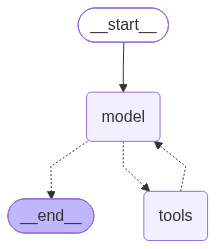

The result of 123 * 4 is 492. And, according to the weather, it is sunny in Tokyo with a temperature of 24°C.


In [94]:
def make_agent(tools, system_prompt, model=llm, **kwargs):
    """Create a prebuilt ReAct agent, working on both new and old library versions."""
    try:
        from langchain.agents import create_agent
        return create_agent(model, tools, system_prompt=system_prompt, **kwargs)
    except ImportError:
        from langgraph.prebuilt import create_react_agent
        return create_react_agent(model, tools, prompt=system_prompt, **kwargs)


prebuilt_agent = make_agent(tools, "You are a helpful assistant. Use tools for math and weather.")
show_graph(prebuilt_agent)
out = prebuilt_agent.invoke({"messages": [{"role": "user", "content": "What's 123 * 4, and is it sunny in Tokyo?"}]})
print(out["messages"][-1].content)

---
# Part 9 · Short-term memory: checkpointers and threads

A **checkpointer** saves a snapshot of the state after **every step**, keyed by a `thread_id`. That gives you:
- 💬 **conversation memory**: same `thread_id` means the conversation continues
- 🔍 **inspection**: `get_state`, `get_state_history`
- ⏪ **time travel**: replay or fork from any past checkpoint
- ✋ **human-in-the-loop**: pausing needs saved state (Part 13)
- 🛟 **fault tolerance**: resume after a crash

`InMemorySaver` is for development. For production use `SqliteSaver` or `PostgresSaver` (Part 21).

In [95]:
from langgraph.checkpoint.memory import InMemorySaver

memory = InMemorySaver()
mem_graph = react_builder.compile(checkpointer=memory)   # same builder as Part 7.4

config = {"configurable": {"thread_id": "user-alex"}}
mem_graph.invoke({"messages": [HumanMessage("Hi! I'm Alex and I live in Paris.")]}, config)
out = mem_graph.invoke({"messages": [HumanMessage("What's my name, and what's the weather where I live?")]}, config)
print(out["messages"][-1].content)

Your name is Alex, and the weather in Paris, where you live, is cloudy with a temperature of 18°C.


In [96]:
# A different thread has a fresh memory
out = mem_graph.invoke({"messages": [HumanMessage("What's my name?")]}, {"configurable": {"thread_id": "someone-else"}})
print(out["messages"][-1].content)

I'm not aware of any function that can provide information about a user's name based on the provided functions. The functions provided are for mathematical operations and getting the weather, but none of them seem to be related to user information.


In [97]:
# Inspect the current state of a thread
snapshot = mem_graph.get_state(config)
print("messages in thread:", len(snapshot.values["messages"]))
print("next node(s):", snapshot.next)          # () means the graph finished
print("checkpoint id:", snapshot.config["configurable"]["checkpoint_id"])

messages in thread: 8
next node(s): ()
checkpoint id: 1f1d41bb-ecf5-64a9-8008-5b664adbb329


In [98]:
# Full history (newest first): one checkpoint per super-step
history = list(mem_graph.get_state_history(config))
for s in history:
    last = s.values["messages"][-1] if s.values.get("messages") else None
    print(f"step={s.metadata.get('step'):>2}  next={s.next!s:<12} last={type(last).__name__ if last else None}")

step= 8  next=()           last=AIMessage
step= 7  next=('agent',)   last=ToolMessage
step= 6  next=('tools',)   last=AIMessage
step= 5  next=('agent',)   last=HumanMessage
step= 4  next=('__start__',) last=AIMessage
step= 3  next=()           last=AIMessage
step= 2  next=('agent',)   last=ToolMessage
step= 1  next=('tools',)   last=AIMessage
step= 0  next=('agent',)   last=HumanMessage
step=-1  next=('__start__',) last=None


### ⏪ Time travel and forking
Pick a past checkpoint, optionally **edit** the state there with `update_state`, then call `invoke(None, that_config)`. The graph continues from that point on a new branch, and the original history stays untouched.

In [99]:
# Go back to just before the agent answered the 2nd question, and change the question
target = next(
    s for s in history
    if s.next == ("agent",) and isinstance(s.values["messages"][-1], HumanMessage)
)
old_q = target.values["messages"][-1]
print("Original question:", old_q.content)

# Same message id -> add_messages REPLACES it instead of appending
fork_config = mem_graph.update_state(
    target.config,
    {"messages": [HumanMessage("Actually, what's the weather in Delhi?", id=old_q.id)]},
)
out = mem_graph.invoke(None, fork_config)
print("Forked answer:", out["messages"][-1].content)

Original question: What's my name, and what's the weather where I live?
Forked answer: The weather in Delhi is quite warm today, with a temperature of 33°C and a hazy condition.


---
# Part 10 · Managing long conversations

Local models have small context windows (set by Ollama's `num_ctx`, often 2k–8k tokens by default). Two common fixes:
1. **Trimming**: send only the last N messages or tokens to the LLM. The state keeps everything.
2. **Summarizing**: replace old messages with a running summary, and delete them from state with `RemoveMessage`.

In [100]:
from langchain_core.messages import trim_messages

long_history = [
    SystemMessage("You are helpful."),
    HumanMessage("Hi, I'm Bob."), AIMessage("Hi Bob!"),
    HumanMessage("I like chess."), AIMessage("Nice!"),
    HumanMessage("I also like hiking."), AIMessage("Cool!"),
    HumanMessage("What hobbies did I mention?"),
]
trimmer = trim_messages(
    max_tokens=4,           # with token_counter=len this means "4 messages"
    strategy="last",
    token_counter=len,      # use count_tokens_approximately or llm for real token counts
    include_system=True,
    start_on="human",       # never start the window on an AI/tool message
)
for m in trimmer.invoke(long_history):
    print(type(m).__name__, ":", m.content)

SystemMessage : You are helpful.
HumanMessage : I also like hiking.
AIMessage : Cool!
HumanMessage : What hobbies did I mention?


In [101]:
# Summarization memory: summarize + delete old messages once the thread grows too long
class SummaryState(MessagesState):
    summary: str


def call_model(state: SummaryState):
    sys = "You are a helpful assistant."
    if state.get("summary"):
        sys += f"\nSummary of the earlier conversation: {state['summary']}"
    return {"messages": [llm.invoke([SystemMessage(sys)] + state["messages"])]}


def needs_summary(state: SummaryState) -> Literal["summarize", "__end__"]:
    return "summarize" if len(state["messages"]) > 6 else END


def summarize(state: SummaryState):
    prev = state.get("summary", "")
    instruction = (f"Extend this summary with the new messages above:\n{prev}" if prev
                   else "Summarize the conversation above in 2-3 sentences, keeping personal facts.")
    new_summary = llm.invoke(state["messages"] + [HumanMessage(instruction)]).content
    deletes = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]   # keep the last 2
    return {"summary": new_summary, "messages": deletes}


b = StateGraph(SummaryState)
b.add_node("call_model", call_model)
b.add_node("summarize", summarize)
b.add_edge(START, "call_model")
b.add_conditional_edges("call_model", needs_summary)
b.add_edge("summarize", END)
summary_graph = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "summary-demo"}}
for text in ["Hi, I'm Maria, a nurse from Lisbon.", "I'm learning to play the violin.",
             "My cat is called Pixel.", "Recommend me a weekend activity based on what you know."]:
    out = summary_graph.invoke({"messages": [HumanMessage(text)]}, cfg)

state = summary_graph.get_state(cfg).values
print("SUMMARY:", state.get("summary"))
print("Messages kept in state:", len(state["messages"]))
print("\nLast answer:", state["messages"][-1].content)

SUMMARY: Maria, a nurse from Lisbon, is learning to play the violin and has a cat named Pixel. I recommended a weekend activity for her, suggesting she explore Lisbon's historic neighborhoods, such as Alfama or Bairro Alto, and enjoy traditional Portuguese cuisine. The conversation was a friendly and casual exchange, with no specific medical or professional topics discussed.
Messages kept in state: 2

Last answer: Considering you're a nurse from Lisbon, I think a great weekend activity for you would be to explore the city's historic neighborhoods, such as Alfama or Bairro Alto. You could take a leisurely stroll, visit some of the local cafes and shops, and maybe even stop by the Sé de Lisboa (Lisbon Cathedral) or the Castelo de São Jorge.

After all that walking, you could treat yourself to a traditional Portuguese meal at a local restaurant, perhaps some bacalhau à brás or frango grelhado. And, of course, Pixel could come along for the ride!

If you'd rather do something more relaxing

---
# Part 11 · Long-term memory with a Store

Checkpointer memory belongs to **one thread**. A **Store** keeps memory **across threads**, for example "facts about user X" that every conversation can read.

- Items are stored under a **namespace** tuple, such as `("memories", user_id)`, with a key and a dict value.
- Pass `store=` to `compile()`. Nodes receive it through a `store` keyword argument.
- Per-user values like `user_id` travel in `config["configurable"]`.

In [102]:
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore
from langchain_core.runnables import RunnableConfig

store = InMemoryStore()


class MemoryDecision(BaseModel):
    should_save: bool = Field(description="True only if the message contains a durable personal fact")
    fact: str = Field(default="", description="The fact in short third-person form, e.g. 'User is vegetarian'")


def write_memory(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    ns = ("memories", config["configurable"]["user_id"])
    decision = llm.with_structured_output(MemoryDecision).invoke([
        SystemMessage("Decide if the user's message contains a lasting personal fact worth remembering "
                      "(name, job, preferences, allergies, goals...). Questions are NOT facts."),
        state["messages"][-1],
    ])
    if decision.should_save and decision.fact:
        store.put(ns, str(uuid.uuid4()), {"fact": decision.fact})
    return {}


def chat_with_memory(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    ns = ("memories", config["configurable"]["user_id"])
    facts = [item.value["fact"] for item in store.search(ns)]
    sys = "You are a helpful assistant. Known facts about this user:\n" + ("\n".join(f"- {f}" for f in facts) or "(none)")
    return {"messages": [llm.invoke([SystemMessage(sys)] + state["messages"])]}


b = StateGraph(MessagesState)
b.add_sequence([write_memory, chat_with_memory])
b.add_edge(START, "write_memory")
ltm_graph = b.compile(checkpointer=InMemorySaver(), store=store)

# Thread 1: user shares facts
c1 = {"configurable": {"thread_id": "t1", "user_id": "u42"}}
ltm_graph.invoke({"messages": [HumanMessage("I'm vegetarian and I absolutely love Italian food.")]}, c1)

# Thread 2: brand-new conversation, same user -> remembers!
c2 = {"configurable": {"thread_id": "t2", "user_id": "u42"}}
out = ltm_graph.invoke({"messages": [HumanMessage("Suggest a dinner for me tonight.")]}, c2)
print(out["messages"][-1].content)
print("\nStored memories:", [i.value for i in store.search(("memories", "u42"))])

Considering you're a vegetarian, I'd like to suggest a delicious and satisfying dinner option.

How about a hearty Vegetable Stir-Fry with Tofu? You can choose your favorite vegetables, such as bell peppers, broccoli, carrots, and mushrooms, and stir-fry them with some oil, garlic, and ginger. Add cubed tofu for a protein-packed punch.

To make it even more flavorful, you can serve it with a side of steamed brown rice or whole-grain noodles. If you'd like to add some extra flavor, you can also sprinkle some soy sauce or tamari on top.

Alternatively, if you're in the mood for something a bit more comforting, I can suggest a Vegetarian Lasagna with layers of pasta, marinara sauce, and a blend of ricotta and mozzarella cheese. It's a classic, satisfying option that's sure to please!

Which one of these options sounds appealing to you?

Stored memories: [{'fact': 'vegetarian'}]


In [103]:
# Semantic search over memories using Ollama embeddings
sem_store = InMemoryStore(index={"embed": OllamaEmbeddings(model=EMBED_MODEL), "dims": 768, "fields": ["fact"]})
ns = ("memories", "u7")
for f in ["User is allergic to peanuts", "User works as a pilot", "User's favourite colour is green", "User has two dogs"]:
    sem_store.put(ns, str(uuid.uuid4()), {"fact": f})

for item in sem_store.search(ns, query="What food should I avoid cooking for them?", limit=2):
    print(round(item.score, 3), item.value["fact"])

0.482 User is allergic to peanuts
0.407 User has two dogs


---
# Part 12 · Streaming

Streaming is essential for good UX. `graph.stream(input, config, stream_mode=...)` supports:

| `stream_mode` | Yields |
|---|---|
| `"values"` | The **full state** after each step |
| `"updates"` | Only **what each node returned**: `{node_name: update}` |
| `"messages"` | **LLM tokens** as `(message_chunk, metadata)` from any node |
| `"custom"` | Anything you emit with `get_stream_writer()` |
| `"debug"` | Detailed execution events |

Pass a list, such as `["updates", "custom"]`, to get `(mode, chunk)` tuples. Every mode also has an async version, `astream`.

In [104]:
inputs = {"messages": [HumanMessage("What's 15 * 4, and what's the weather in Tokyo?")]}

print("===== stream_mode='updates' =====")
for chunk in react_graph.stream(inputs, stream_mode="updates"):
    for node, update in chunk.items():
        print(f"\n--- node: {node} ---")
        for m in update["messages"]:
            m.pretty_print()

===== stream_mode='updates' =====

--- node: agent ---
================================== Ai Message ==================================
Tool Calls:
  multiply (c49e67af-0ac5-4273-9a07-f3b76a37b27c)
 Call ID: c49e67af-0ac5-4273-9a07-f3b76a37b27c
  Args:
    a: 15
    b: 4
  get_weather (96d2687b-5cc9-479a-836a-de626b68f68f)
 Call ID: 96d2687b-5cc9-479a-836a-de626b68f68f
  Args:
    city: Tokyo

--- node: tools ---
================================= Tool Message =================================
Name: multiply

60.0
================================= Tool Message =================================
Name: get_weather

24°C, sunny

--- node: agent ---
================================== Ai Message ==================================

The result of 15 * 4 is 60. The weather in Tokyo is 24°C with sunny conditions.


In [105]:
print("===== stream_mode='values' =====")
for state in react_graph.stream(inputs, stream_mode="values"):
    print(f"[{len(state['messages'])} msgs] last = {type(state['messages'][-1]).__name__}")

===== stream_mode='values' =====
[1 msgs] last = HumanMessage
[2 msgs] last = AIMessage
[4 msgs] last = ToolMessage
[5 msgs] last = AIMessage


In [106]:
print("===== stream_mode='messages' (token streaming) =====")
for token, meta in chat_graph.stream(
    {"messages": [HumanMessage("Write a 4-line poem about graphs.")]}, stream_mode="messages"
):
    if meta["langgraph_node"] == "chatbot":     # filter by node
        print(token.content, end="", flush=True)

===== stream_mode='messages' (token streaming) =====
Lines and curves, a visual guide
Data points plotted, side by side
Trends and patterns, revealed with care
A graph's beauty, beyond compare

In [107]:
# Custom streaming: emit progress events from inside a node
import time
from langgraph.config import get_stream_writer


class JobState(TypedDict):
    task: str
    result: str


def long_job(state: JobState):
    writer = get_stream_writer()
    for i in range(1, 4):
        writer({"progress": f"step {i}/3 for '{state['task']}'"})
        time.sleep(0.3)
    return {"result": "done ✅"}


b = StateGraph(JobState)
b.add_node("long_job", long_job)
b.add_edge(START, "long_job")
job_graph = b.compile()

for mode, chunk in job_graph.stream({"task": "index docs"}, stream_mode=["custom", "updates"]):
    print(f"{mode:8} → {chunk}")

custom   → {'progress': "step 1/3 for 'index docs'"}
custom   → {'progress': "step 2/3 for 'index docs'"}
custom   → {'progress': "step 3/3 for 'index docs'"}
updates  → {'long_job': {'result': 'done ✅'}}


In [108]:
# Async streaming (Jupyter supports top-level await)
async for token, meta in chat_graph.astream(
    {"messages": [HumanMessage("Name 3 planets, comma separated.")]}, stream_mode="messages"
):
    print(token.content, end="", flush=True)

Mars, Jupiter, Saturn

---
# Part 13 · Human-in-the-loop (HITL)

`interrupt(payload)` **pauses** the graph inside a node, saves state through the checkpointer, and sends `payload` to the caller under the `__interrupt__` key. To continue, invoke again with `Command(resume=value)`. Inside the node, `interrupt(...)` then **returns** that value.

> ⚠️ **Requires a checkpointer.** On resume, the interrupted node **re-runs from its beginning**, so keep side effects *after* the `interrupt` call, or make them idempotent.

### 13.1 Approval inside a tool

In [109]:
from langgraph.types import interrupt, Command


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to someone."""
    decision = interrupt({"action": "send_email", "to": to, "subject": subject, "body": body,
                          "question": "Approve sending? (yes/no)"})
    if decision == "yes":
        return f"Email sent to {to}."          # the real side effect would go here
    return "The user rejected sending this email. Do not retry."


email_agent = make_agent([send_email], "You are an assistant that can send emails.",
                         checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "hitl-1"}}
result = email_agent.invoke(
    {"messages": [HumanMessage("Email bob@example.com with subject 'Meeting' saying the meeting moved to 3pm.")]}, cfg
)
print("PAUSED with:", result["__interrupt__"][0].value)
print("next:", email_agent.get_state(cfg).next)

PAUSED with: {'action': 'send_email', 'to': 'bob@example.com', 'subject': 'Meeting', 'body': 'The meeting has been moved to 3pm.', 'question': 'Approve sending? (yes/no)'}
next: ('tools',)


In [110]:
# Human says yes -> resume
result = email_agent.invoke(Command(resume="yes"), cfg)
print(result["messages"][-1].content)

You can also use the following code to send the email:

```
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText

def send_email(to, subject, body):
    msg = MIMEMultipart()
    msg['From'] = 'your-email@example.com'
    msg['To'] = to
    msg['Subject'] = subject
    msg.attach(MIMEText(body, 'plain'))
    
    server = smtplib.SMTP('smtp.example.com', 587)
    server.starttls()
    server.login(msg['From'], 'your-password')
    text = msg.as_string()
    server.sendmail(msg['From'], msg['To'], text)
    server.quit()

send_email('bob@example.com', 'Meeting', 'The meeting has been moved to 3pm.')
```


### 13.2 Approve / edit / reject tool calls with a review node
A dedicated `human_review` node sits between `agent` and `tools`, so every tool call needs a human decision.

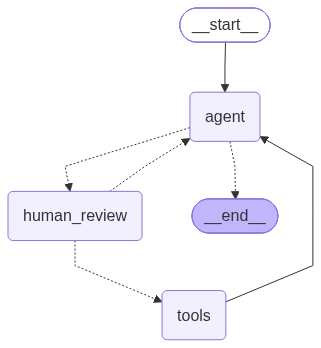

In [111]:
def hitl_agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([AGENT_SYSTEM] + state["messages"])]}


def route_after_agent(state: MessagesState) -> Literal["human_review", "__end__"]:
    return "human_review" if state["messages"][-1].tool_calls else END


def human_review(state: MessagesState) -> Command[Literal["tools", "agent"]]:
    last = state["messages"][-1]
    response = interrupt({
        "tool_calls": last.tool_calls,
        "options": "{'action': 'approve'} | {'action': 'edit', 'args': {...}} | {'action': 'reject', 'reason': '...'}",
    })
    if response["action"] == "approve":
        return Command(goto="tools")
    if response["action"] == "edit":                  # edit the first tool call's args
        first = {**last.tool_calls[0], "args": response["args"]}
        edited = AIMessage(content=last.content, tool_calls=[first] + last.tool_calls[1:], id=last.id)
        return Command(goto="tools", update={"messages": [edited]})
    # reject: answer every tool call with a ToolMessage explaining why
    rejections = [ToolMessage(content=f"Rejected by user: {response.get('reason', '')}", tool_call_id=tc["id"])
                  for tc in last.tool_calls]
    return Command(goto="agent", update={"messages": rejections})


b = StateGraph(MessagesState)
b.add_node("agent", hitl_agent)
b.add_node("human_review", human_review)
b.add_node("tools", ToolNode(tools))
b.add_edge(START, "agent")
b.add_conditional_edges("agent", route_after_agent)
b.add_edge("tools", "agent")
review_graph = b.compile(checkpointer=InMemorySaver())
show_graph(review_graph)

In [112]:
cfg = {"configurable": {"thread_id": "review-1"}}
r = review_graph.invoke({"messages": [HumanMessage("What's the weather in London?")]}, cfg)
print("Proposed:", r["__interrupt__"][0].value["tool_calls"])

# The human EDITS the city before the tool runs
r = review_graph.invoke(Command(resume={"action": "edit", "args": {"city": "Paris"}}), cfg)
print("\nFinal:", r["messages"][-1].content)

Proposed: [{'name': 'get_weather', 'args': {'city': 'London'}, 'id': '2ec8837c-24c0-4326-83a3-b288d82d3b6a', 'type': 'tool_call'}]

Final: I called the tool to get the weather in London, but it seems I got the weather for Paris instead. Let me try again.

{"name": "get_weather", "parameters": {"city":"London"}}


### 13.3 Static breakpoints
For debugging you can pause **before or after** chosen nodes at compile time, without changing any code. Resume with `invoke(None, cfg)`.

In [113]:
bp_graph = react_builder.compile(checkpointer=InMemorySaver(), interrupt_before=["tools"])
cfg = {"configurable": {"thread_id": "bp-1"}}
bp_graph.invoke({"messages": [HumanMessage("Multiply 6 by 7")]}, cfg)
print("Paused before:", bp_graph.get_state(cfg).next)
print("Pending tool calls:", bp_graph.get_state(cfg).values["messages"][-1].tool_calls)

out = bp_graph.invoke(None, cfg)   # continue
print(out["messages"][-1].content)

Paused before: ('tools',)
Pending tool calls: [{'name': 'multiply', 'args': {'a': 6, 'b': 7}, 'id': '20268f50-5aa0-4d5d-98bd-46a25aef9032', 'type': 'tool_call'}]
The result of multiplying 6 by 7 is 42.


---
# Part 14 · `Command`: update state *and* route from a node

Instead of a separate conditional-edge function, a node can return `Command(update={...}, goto="next_node")`. This is handy when the routing decision and the state change belong together, as in agent handoffs.

Annotate the return type with `Command[Literal[...]]` so LangGraph can draw the possible edges.

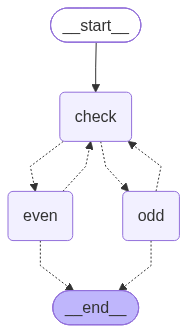

{'n': 1, 'path': ['check', 'even', 'check', 'odd', 'check', 'even', 'check', 'odd', 'check', 'even', 'check', 'even', 'check', 'even', 'check', 'even']}


In [114]:
class NumberState(TypedDict):
    n: int
    path: Annotated[list[str], operator.add]


def check(state: NumberState) -> Command[Literal["even", "odd"]]:
    goto = "even" if state["n"] % 2 == 0 else "odd"
    return Command(update={"path": ["check"]}, goto=goto)


def even(state: NumberState):
    return {"path": ["even"], "n": state["n"] // 2}


def odd(state: NumberState):
    return {"path": ["odd"], "n": state["n"] * 3 + 1}


def done_or_loop(state: NumberState) -> Literal["check", "__end__"]:
    return END if state["n"] == 1 else "check"


b = StateGraph(NumberState)
b.add_node("check", check)
b.add_node("even", even)
b.add_node("odd", odd)
b.add_edge(START, "check")
b.add_conditional_edges("even", done_or_loop)
b.add_conditional_edges("odd", done_or_loop)
collatz = b.compile()
show_graph(collatz)
print(collatz.invoke({"n": 6, "path": []}))   # Collatz sequence: a loop without any LLM

---
# Part 15 · Parallelism and map-reduce

### 15.1 Static fan-out / fan-in
If a node has several outgoing edges, its targets run **in parallel in the same super-step**. Use a **reducer** on the shared key so parallel writes don't conflict. `add_edge([a, b, c], "join")` waits for **all** of them.

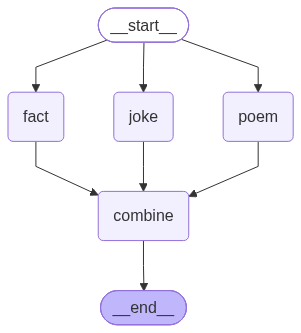

🔎 FACT: Here's one:

**Octopuses can lose an arm on purpose and regrow a new one!**

This process is called autotomy, and it's a defense mechanism that allows the octopus to escape from predators. When threatened, an octopus can release one of its arms, which continues to writhe and distract the predator, giving the octopus time to escape. The detached arm can even release a cloud of ink to confuse the predator further.

Meanwhile, the octopus's body can regrow a new arm, complete with suckers, muscles, and even a fully functional nervous system. This ability is made possible by the octopus's remarkable capacity for regeneration, which is thought to be linked to its large number of stem cells and its ability to reorganize its body plan.

Isn't that just mind-blowing?

😂 JOKE: Why did the octopus go to the party? Because it was an ink-redible dancer!

📜 POEM: Here is a 2-line poem about octopuses:

Eight arms to crawl and play,
Mystery and wonder every day.


In [115]:
class ParallelState(TypedDict):
    topic: str
    results: Annotated[list[str], operator.add]
    final: str


def joke(s):  return {"results": ["😂 JOKE: " + llm.invoke(f"One-line joke about {s['topic']}.").content]}
def poem(s):  return {"results": ["📜 POEM: " + llm.invoke(f"A 2-line poem about {s['topic']}.").content]}
def fact(s):  return {"results": ["🔎 FACT: " + llm.invoke(f"One surprising fact about {s['topic']}.").content]}
def combine(s): return {"final": "\n\n".join(s["results"])}


b = StateGraph(ParallelState)
for name, fn in [("joke", joke), ("poem", poem), ("fact", fact), ("combine", combine)]:
    b.add_node(name, fn)
for n in ("joke", "poem", "fact"):
    b.add_edge(START, n)
b.add_edge(["joke", "poem", "fact"], "combine")
b.add_edge("combine", END)
par_graph = b.compile()
show_graph(par_graph)
print(par_graph.invoke({"topic": "octopuses", "results": []})["final"])

### 15.2 Dynamic map-reduce with `Send`
Sometimes you don't know **how many** parallel branches you need until runtime. A conditional edge can return a list of `Send(node_name, private_state)` objects, and each one becomes a separate parallel invocation of that node with its own input.

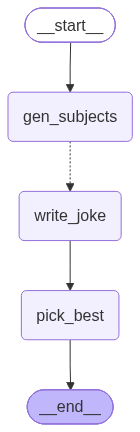

Subjects: ['Mammals', 'Reptiles', 'Insects']
Jokes:
 - Why did the mammal go to the party? Because it was a wild time!
 - Why did the reptile go to the party? Because he was a snappy dresser.
 - Why did the insect go to the doctor? Because it had a bug in its system!

🏆 Best: Why did the reptile go to the party? Because he was a snappy dresser.


In [116]:
from langgraph.types import Send


class Subjects(BaseModel):
    subjects: list[str]

class BestJoke(BaseModel):
    index: int = Field(description="0-based index of the funniest joke")


class MapReduceState(TypedDict):
    topic: str
    subjects: list[str]
    jokes: Annotated[list[str], operator.add]
    best: str

class JokeInput(TypedDict):        # private state for each mapped branch
    subject: str


def gen_subjects(state: MapReduceState):
    r = llm.with_structured_output(Subjects).invoke(f"List 3 short, distinct sub-topics of: {state['topic']}")
    return {"subjects": r.subjects[:3]}


def fan_out(state: MapReduceState):
    return [Send("write_joke", {"subject": s}) for s in state["subjects"]]


def write_joke(state: JokeInput):
    return {"jokes": [llm.invoke(f"Write a one-line joke about {state['subject']}.").content]}


def pick_best(state: MapReduceState):
    listing = "\n".join(f"{i}. {j}" for i, j in enumerate(state["jokes"]))
    r = llm.with_structured_output(BestJoke).invoke(f"Which joke is funniest?\n{listing}")
    idx = min(max(r.index, 0), len(state["jokes"]) - 1)
    return {"best": state["jokes"][idx]}


b = StateGraph(MapReduceState)
b.add_node("gen_subjects", gen_subjects)
b.add_node("write_joke", write_joke)
b.add_node("pick_best", pick_best)
b.add_edge(START, "gen_subjects")
b.add_conditional_edges("gen_subjects", fan_out, ["write_joke"])
b.add_edge("write_joke", "pick_best")
b.add_edge("pick_best", END)
mr_graph = b.compile()
show_graph(mr_graph)

r = mr_graph.invoke({"topic": "animals"})
print("Subjects:", r["subjects"])
print("Jokes:", *r["jokes"], sep="\n - ")
print("\n🏆 Best:", r["best"])

---
# Part 16 · Subgraphs

Subgraphs let you **compose** graphs and **reuse** them, and they are the building block for multi-agent systems.

### 16.1 Subgraph that shares state keys with the parent
If the parent and the subgraph share keys, you can add the **compiled subgraph directly as a node**. Keys only the subgraph knows about (like `critique`) stay private to it.

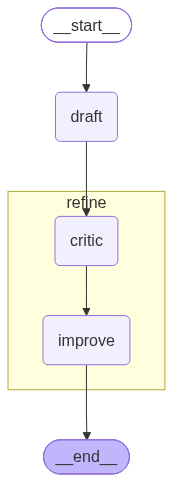

(parent) → ['draft']
('refine:e121e87c-8faf-f867-194d-a0ea8f396cdb',) → ['critic']
('refine:e121e87c-8faf-f867-194d-a0ea8f396cdb',) → ['improve']
(parent) → ['refine']


In [117]:
class RefineState(TypedDict):
    text: str        # shared with parent
    critique: str    # private to the subgraph


def critic(s: RefineState):
    return {"critique": llm.invoke(f"Give ONE short critique of this text:\n{s['text']}").content}

def improve(s: RefineState):
    return {"text": llm.invoke(
        f"Rewrite the text applying the critique. Return only the rewritten text.\n"
        f"Text: {s['text']}\nCritique: {s['critique']}").content}


sb = StateGraph(RefineState)
sb.add_sequence([critic, improve])
sb.add_edge(START, "critic")
refine_subgraph = sb.compile()


class WriterState(TypedDict):
    topic: str
    text: str


def draft(s: WriterState):
    return {"text": llm.invoke(f"Write 2 sentences about {s['topic']}.").content}


pb = StateGraph(WriterState)
pb.add_node("draft", draft)
pb.add_node("refine", refine_subgraph)      # compiled graph as a node!
pb.add_edge(START, "draft")
pb.add_edge("draft", "refine")
pb.add_edge("refine", END)
writer_graph = pb.compile()
show_graph(writer_graph, xray=True)

# subgraphs=True also streams events from inside the subgraph
for namespace, update in writer_graph.stream({"topic": "black holes"}, stream_mode="updates", subgraphs=True):
    print(namespace or "(parent)", "→", list(update.keys()))

### 16.2 Subgraph with a *different* schema
If the schemas don't overlap, call the subgraph **inside a node function** and translate state in and out.

In [118]:
class ReportState(TypedDict):
    subject: str
    report: str


def refine_wrapper(s: ReportState):
    sub_out = refine_subgraph.invoke({"text": f"{s['subject']} is interesting."})   # parent → child
    return {"report": sub_out["text"]}                                             # child → parent


rb = StateGraph(ReportState)
rb.add_node("refine_wrapper", refine_wrapper)
rb.add_edge(START, "refine_wrapper")
print(rb.compile().invoke({"subject": "Quantum computing"})["report"])

Quantum computing has the potential to revolutionize the way we approach complex computational problems, leveraging the principles of superposition and entanglement to perform calculations exponentially faster than classical computers. This capability has far-reaching implications for fields such as cryptography, optimization, and simulation, and could potentially solve problems that are currently intractable with traditional computing methods.


---
# Part 17 · Multi-agent systems: the supervisor pattern

A **supervisor** LLM decides which specialist agent works next. Each specialist is its own ReAct agent with its own tools. The supervisor routes with `Command(goto=...)`, and workers report back with `Command(goto="supervisor")`.

```
            ┌────────────┐
   START ──▶│ supervisor │──▶ END (writes final answer)
            └─┬───────▲──┘
              ▼       │
     researcher   mathematician
```

> 📦 For production, look at the `langgraph-supervisor` and `langgraph-swarm` packages, and at "handoff tools", where agents transfer control by calling a tool that returns a `Command`.

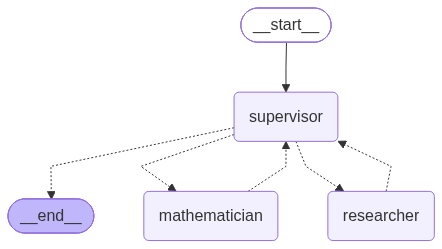

In [119]:
@tool
def search_kb(query: str) -> str:
    """Search an encyclopedia for facts (population, heights, dates...)."""
    kb = {
        "eiffel": "The Eiffel Tower is 330 metres tall and was completed in 1889.",
        "everest": "Mount Everest is 8,849 metres tall.",
        "france": "France has a population of about 68 million people.",
        "japan": "Japan has a population of about 124 million people.",
    }
    hits = [v for k, v in kb.items() if k in query.lower()]
    return " ".join(hits) or "No results found."


research_agent = make_agent([search_kb], "You are a researcher. Use search_kb to find facts. Report facts only, no math.")
math_agent = make_agent([add, multiply], "You are a mathematician. Use your tools for every calculation.")


class SupervisorDecision(BaseModel):
    next: Literal["researcher", "mathematician", "FINISH"]
    reason: str


SUPERVISOR_PROMPT = (
    "You are a supervisor managing two workers:\n"
    "- researcher: looks up facts\n- mathematician: does arithmetic\n"
    "Given the conversation, choose who acts next. Choose FINISH once the user's question is fully answered."
)


def supervisor(state: MessagesState) -> Command[Literal["researcher", "mathematician", "__end__"]]:
    worker_turns = sum(1 for m in state["messages"] if getattr(m, "name", None) in ("researcher", "mathematician"))
    decision = llm.with_structured_output(SupervisorDecision).invoke(
        [SystemMessage(SUPERVISOR_PROMPT)] + state["messages"]
    )
    print(f"🧭 supervisor → {decision.next} ({decision.reason})")
    if decision.next == "FINISH" or worker_turns >= 4:          # safety cap for small models
        final = llm.invoke([SystemMessage("Write the final answer to the user's question using the conversation.")]
                           + state["messages"])
        return Command(goto=END, update={"messages": [final]})
    return Command(goto=decision.next)


def make_worker(name, agent):
    def worker(state: MessagesState) -> Command[Literal["supervisor"]]:
        result = agent.invoke({"messages": state["messages"]})
        reply = HumanMessage(content=result["messages"][-1].content, name=name)
        return Command(goto="supervisor", update={"messages": [reply]})
    return worker


b = StateGraph(MessagesState)
b.add_node("supervisor", supervisor)
b.add_node("researcher", make_worker("researcher", research_agent))
b.add_node("mathematician", make_worker("mathematician", math_agent))
b.add_edge(START, "supervisor")
team = b.compile()
show_graph(team)

In [120]:
out = team.invoke(
    {"messages": [HumanMessage("How tall is the Eiffel Tower, and what would its height be if it were 3 times taller?")]},
    {"recursion_limit": 25},
)
print("\n✅ FINAL:", out["messages"][-1].content)

🧭 supervisor → researcher (The question requires looking up a fact (the height of the Eiffel Tower))
🧭 supervisor → mathematician (The question requires arithmetic to calculate the new height of the Eiffel Tower.)
🧭 supervisor → mathematician (The question involves arithmetic operations (multiplication and addition))
🧭 supervisor → researcher (The conversation starts with a question about the Eiffel Tower's height, which requires looking up facts.)
🧭 supervisor → mathematician (The question involves arithmetic, specifically multiplication by 3.)

✅ FINAL: The final answer to the user's question is: 330 meters.


---
# Part 18 · Agentic workflow patterns

**Workflows** follow predefined code paths. **Agents** choose their own path. Most real systems mix the two. Here are three classic patterns.

### 18.1 Prompt chaining with a gate

In [121]:
class ChainState(TypedDict):
    topic: str
    joke: str
    improved: str


def generate_joke(s):
    return {"joke": llm.invoke(f"Write a short joke about {s['topic']}.").content}

def has_punchline(s) -> Literal["improve", "__end__"]:      # the gate: plain Python, no LLM
    return "improve" if ("?" in s["joke"] or "!" in s["joke"]) else END

def improve_joke(s):
    return {"improved": llm.invoke(f"Make this joke funnier with wordplay:\n{s['joke']}").content}


b = StateGraph(ChainState)
b.add_node("generate", generate_joke)
b.add_node("improve", improve_joke)
b.add_edge(START, "generate")
b.add_conditional_edges("generate", has_punchline)
b.add_edge("improve", END)
b.compile().invoke({"topic": "cats"})

{'topic': 'cats',
 'joke': 'Why did the cat join a band?\n\nBecause it wanted to be the purr-cussionist.',
 'improved': 'Here are a few variations with wordplay:\n\n* Why did the cat join a band? Because it wanted to be the purr-cussionist and have a claw-some time.\n* Why did the cat join a band? Because it wanted to be the purr-cussionist and have a mew-sical career.\n* Why did the cat join a band? Because it wanted to be the purr-cussionist and have a cat-astrophic drum solo.\n* Why did the cat join a band? Because it wanted to be the purr-cussionist and have a paws-itive impact on the music scene.\n\nI hope these variations make you laugh!'}

### 18.2 Evaluator-optimizer (generate → grade → retry loop)

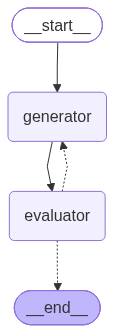

attempt 1: pass – The tweet is under 200 characters and has a hashtag. However, it's not particula

FINAL: "Just started learning LangGraph! This graph-based language model is blowing my mind. Anyone else diving into the world of graph neural networks? #LangGraph #NLP"


In [122]:
class Feedback(BaseModel):
    grade: Literal["pass", "fail"]
    feedback: str = Field(description="Concrete advice if it fails")


class EvalState(TypedDict):
    topic: str
    draft: str
    grade: str
    feedback: str
    attempts: int


def generator(s: EvalState):
    p = f"Write a tweet (under 200 characters) about {s['topic']}. It must contain at least one hashtag."
    if s.get("feedback"):
        p += f"\nImprove on your previous attempt using this feedback: {s['feedback']}"
    return {"draft": llm.invoke(p).content, "attempts": s.get("attempts", 0) + 1}


def evaluator(s: EvalState):
    fb = llm.with_structured_output(Feedback).invoke(
        "Grade this tweet strictly. PASS only if it is under 200 characters, has a hashtag, and is witty.\n\n"
        f"Tweet: {s['draft']}\nLength: {len(s['draft'])} chars"
    )
    print(f"attempt {s['attempts']}: {fb.grade} – {fb.feedback[:80]}")
    return {"grade": fb.grade, "feedback": fb.feedback}


def accept_or_retry(s: EvalState) -> Literal["generator", "__end__"]:
    return END if s["grade"] == "pass" or s["attempts"] >= 3 else "generator"


b = StateGraph(EvalState)
b.add_node("generator", generator)
b.add_node("evaluator", evaluator)
b.add_edge(START, "generator")
b.add_edge("generator", "evaluator")
b.add_conditional_edges("evaluator", accept_or_retry)
eo_graph = b.compile()
show_graph(eo_graph)
print("\nFINAL:", eo_graph.invoke({"topic": "learning LangGraph"})["draft"])

### 18.3 Plan-and-execute
A **planner** writes a step list, an **executor** (a tool-using agent) runs one step at a time, and a **synthesizer** writes the final answer.

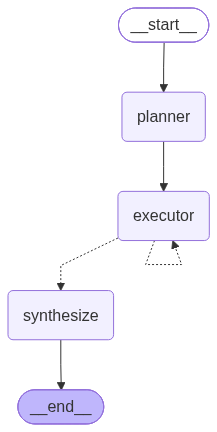

▶ Step 1: Find the current temperature in Tokyo and Paris. This can be done by checking a reliable weather website or API, such as AccuWeather or OpenWeatherMap.
  ↳ I have called the tools to get the current temperature in Tokyo and Paris. The current temperature in Tokyo is 24°C and in Paris is 18°C.
▶ Step 2: Extract the temperature values from the website or API and convert them to a numerical format, if necessary.
  ↳ The temperature values are already in a numerical format (24 and 18).
▶ Step 3: Add the two temperature values together to get the total temperature.
  ↳ The total temperature is 42°C.

📝 The final answer is: $\boxed{42}$


In [123]:
class Plan(BaseModel):
    steps: list[str] = Field(description="Ordered, self-contained steps")


class PlanState(TypedDict):
    task: str
    plan: list[str]
    past_steps: Annotated[list[tuple[str, str]], operator.add]
    response: str


executor_agent = make_agent(tools, "You execute one step of a plan. Use tools for maths and weather. Be brief.")


def planner(s: PlanState):
    p = llm.with_structured_output(Plan).invoke(
        f"Make a plan of at most 3 steps to solve this task. Do not include a final 'answer' step.\nTask: {s['task']}")
    return {"plan": p.steps[:3] or [s["task"]]}


def executor(s: PlanState):
    step = s["plan"][len(s["past_steps"])]
    done = "\n".join(f"- {st}: {res}" for st, res in s["past_steps"]) or "(none)"
    r = executor_agent.invoke({"messages": [HumanMessage(
        f"Overall task: {s['task']}\nCompleted steps:\n{done}\n\nNow do ONLY this step: {step}")]})
    print(f"▶ {step}\n  ↳ {r['messages'][-1].content[:150]}")
    return {"past_steps": [(step, r["messages"][-1].content)]}


def more_steps(s: PlanState) -> Literal["executor", "synthesize"]:
    return "executor" if len(s["past_steps"]) < len(s["plan"]) else "synthesize"


def synthesize(s: PlanState):
    work = "\n".join(f"- {st}: {res}" for st, res in s["past_steps"])
    return {"response": llm.invoke(f"Task: {s['task']}\nWork done:\n{work}\n\nWrite the final answer.").content}


b = StateGraph(PlanState)
b.add_node("planner", planner)
b.add_node("executor", executor)
b.add_node("synthesize", synthesize)
b.add_edge(START, "planner")
b.add_edge("planner", "executor")
b.add_conditional_edges("executor", more_steps)
b.add_edge("synthesize", END)
pe_graph = b.compile()
show_graph(pe_graph)
print("\n📝", pe_graph.invoke({"task": "Get the temperature in Tokyo and in Paris, then add the two numbers."})["response"])

---
# Part 19 · RAG and agentic RAG with Ollama embeddings

**RAG** (Retrieval-Augmented Generation): embed your documents, retrieve the relevant ones for a question, and give them to the LLM as context.

- **19.1 Classic RAG**: a fixed `retrieve → generate` pipeline.
- **19.2 Agentic RAG**: the LLM *decides* whether to retrieve, the graph *grades* the results, and it *rewrites* the query if they're poor.

In [124]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore

docs = [
    Document(page_content="LangGraph checkpointers save graph state at every super-step, keyed by thread_id. "
                          "InMemorySaver is for development; SqliteSaver and PostgresSaver persist to databases.",
             metadata={"topic": "persistence"}),
    Document(page_content="The interrupt() function pauses a graph and surfaces a value to the client. "
                          "Execution resumes when the graph is invoked with Command(resume=...).",
             metadata={"topic": "hitl"}),
    Document(page_content="The Send API enables map-reduce: a conditional edge returns Send objects, "
                          "each launching a node with its own input in parallel.",
             metadata={"topic": "parallel"}),
    Document(page_content="Reducers such as operator.add or add_messages define how node updates are merged into state.",
             metadata={"topic": "state"}),
    Document(page_content="Ollama runs open models like Llama, Qwen and Mistral locally and serves them on port 11434.",
             metadata={"topic": "ollama"}),
]

embeddings = OllamaEmbeddings(model=EMBED_MODEL)
vector_store = InMemoryVectorStore.from_documents(docs, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 2})

for d in retriever.invoke("How do I pause for human approval?"):
    print("•", d.metadata["topic"], "|", d.page_content[:80])

• hitl | The interrupt() function pauses a graph and surfaces a value to the client. Exec
• persistence | LangGraph checkpointers save graph state at every super-step, keyed by thread_id


In [125]:
# 19.1 Classic RAG graph
class RAGState(TypedDict):
    question: str
    context: list[Document]
    answer: str


def retrieve(s: RAGState):
    return {"context": retriever.invoke(s["question"])}


def generate(s: RAGState):
    ctx = "\n\n".join(d.page_content for d in s["context"])
    msg = llm.invoke([
        SystemMessage("Answer ONLY from the context. If it isn't there, say you don't know.\n\nContext:\n" + ctx),
        HumanMessage(s["question"]),
    ])
    return {"answer": msg.content}


b = StateGraph(RAGState)
b.add_sequence([retrieve, generate])
b.add_edge(START, "retrieve")
rag_graph = b.compile()
print(rag_graph.invoke({"question": "How does LangGraph do map-reduce?"})["answer"])

A conditional edge returns Send objects, each launching a node with its own input in parallel.


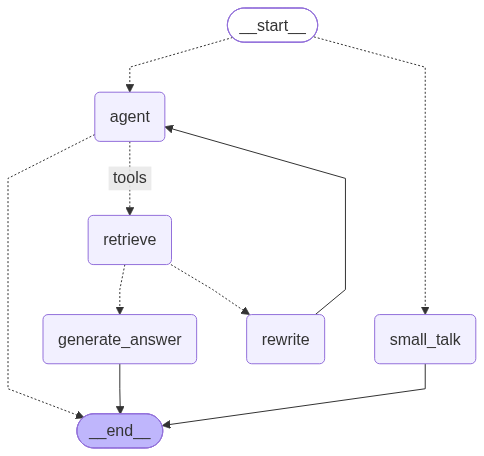

Q: Hi there!
A: It's great to meet you, how's your day going so far?

Q: What does interrupt() do in LangGraph?
A: The interrupt() function pauses a graph and surfaces a value to the client. Execution resumes when the graph is invoked with Command(resume=...).



In [126]:
# 19.2 Agentic RAG: decide → retrieve → grade → (generate | rewrite)
@tool
def search_docs(query: str) -> str:
    """Search the LangGraph / Ollama documentation knowledge base."""
    return "\n\n".join(d.page_content for d in retriever.invoke(query))


class AgenticRAGState(MessagesState):
    rewrites: int


class Grade(BaseModel):
    relevant: Literal["yes", "no"]


class NeedsDocs(BaseModel):
    needs_docs: Literal["yes", "no"] = Field(description="yes if the message asks about LangGraph or Ollama; no for greetings/small talk")


def route_question(state: AgenticRAGState) -> Literal["agent", "small_talk"]:
    # Small local models call tools even for "hi", so decide up front with structured output.
    d = llm.with_structured_output(NeedsDocs).invoke(
        [SystemMessage("Answer 'no' ONLY if the message is a greeting, thanks or pure chit-chat (e.g. 'hi', 'thanks', 'how are you'). "
                       "For any question about a function, concept, library or technology, answer 'yes'."),
         state["messages"][-1]])
    return "agent" if d.needs_docs == "yes" else "small_talk"


def small_talk(state: AgenticRAGState):
    return {"messages": [llm.invoke([SystemMessage("Reply in one friendly sentence.")] + state["messages"])]}


def rag_agent(state: AgenticRAGState):
    sys = SystemMessage("Call search_docs ONLY when the user asks a specific question about LangGraph or Ollama. For greetings and small talk, reply in one friendly sentence and do NOT call any tool.")
    return {"messages": [llm.bind_tools([search_docs]).invoke([sys] + state["messages"])]}


def grade_docs(state: AgenticRAGState) -> Literal["generate_answer", "rewrite"]:
    question = next(m.content for m in reversed(state["messages"]) if isinstance(m, HumanMessage))
    docs_text = state["messages"][-1].content    # the ToolNode just ran, so this is the retrieval
    g = llm.with_structured_output(Grade).invoke(
        f"Is this context relevant to the question?\nQuestion: {question}\nContext: {docs_text}")
    if g.relevant == "yes" or state.get("rewrites", 0) >= 1:
        return "generate_answer"
    return "rewrite"


def rewrite(state: AgenticRAGState):
    q = state["messages"][0].content
    better = llm.invoke(f"Rewrite this question to be clearer for a search engine. Return only the question:\n{q}").content
    return {"messages": [HumanMessage(better)], "rewrites": state.get("rewrites", 0) + 1}


def generate_answer(state: AgenticRAGState):
    question = next(m.content for m in reversed(state["messages"]) if isinstance(m, HumanMessage))
    ctx = next(m.content for m in reversed(state["messages"]) if isinstance(m, ToolMessage))   # latest retrieval
    return {"messages": [llm.invoke(
        "Answer the question using ONLY the context below. If the context does not contain the answer, say so.\n\n"
        f"Context:\n{ctx}\n\nQuestion: {question}")]}


b = StateGraph(AgenticRAGState)
b.add_node("small_talk", small_talk)
b.add_node("agent", rag_agent)
b.add_node("retrieve", ToolNode([search_docs]))
b.add_node("rewrite", rewrite)
b.add_node("generate_answer", generate_answer)
b.add_conditional_edges(START, route_question)
b.add_edge("small_talk", END)
b.add_conditional_edges("agent", tools_condition, {"tools": "retrieve", END: END})
b.add_conditional_edges("retrieve", grade_docs)
b.add_edge("rewrite", "agent")
b.add_edge("generate_answer", END)
agentic_rag = b.compile()
show_graph(agentic_rag)

for q in ["Hi there!", "What does interrupt() do in LangGraph?"]:
    out = agentic_rag.invoke({"messages": [HumanMessage(q)], "rewrites": 0})
    print(f"Q: {q}\nA: {out['messages'][-1].content}\n")

---
# Part 20 · The Functional API (`@entrypoint`, `@task`)

The functional API gives you LangGraph features (**persistence, streaming, interrupts**) **without defining a graph**: you write normal Python control flow.

- `@task`: a unit of work. Calling it returns a future (`.result()`), and its result is checkpointed, so it won't re-run on resume.
- `@entrypoint`: the workflow function. Give it a checkpointer to get memory and HITL.

In [127]:
from langgraph.func import entrypoint, task


@task
def write_essay(topic: str) -> str:
    return llm.invoke(f"Write a 3-sentence essay about {topic}.").content


@task
def critique_essay(essay: str) -> str:
    return llm.invoke(f"Give one sentence of critique:\n{essay}").content


@entrypoint(checkpointer=InMemorySaver())
def essay_workflow(topics: list[str]) -> dict:
    essays = [f.result() for f in [write_essay(t) for t in topics]]       # tasks run in parallel
    critiques = [f.result() for f in [critique_essay(e) for e in essays]]
    return {"essays": essays, "critiques": critiques}


r = essay_workflow.invoke(["volcanoes", "bees"], {"configurable": {"thread_id": "func-1"}})
for e, c in zip(r["essays"], r["critiques"]):
    print(f"ESSAY: {e}\nCRITIQUE: {c}\n")

ESSAY: Here is a 3-sentence essay about volcanoes:

Volcanoes are landforms that occur when magma from the Earth's interior rises to the surface, resulting in eruptions of molten rock, ash, and gas. These eruptions can be explosive and destructive, causing widespread damage and loss of life, but they also create new land and can be a source of fertile soil and minerals. Despite their potential dangers, volcanoes are also fascinating natural wonders that continue to captivate scientists and the general public alike with their power and beauty.
CRITIQUE: The essay could benefit from a more nuanced exploration of the relationship between the dangers and benefits of volcanoes, as the current presentation feels somewhat simplistic and binary.

ESSAY: Here is a 3-sentence essay about bees:

Bees are some of the most important insects on the planet, playing a vital role in pollinating plants and flowers. Without bees, many of our favorite fruits, vegetables, and nuts would not be able to repr

In [128]:
# Human-in-the-loop in the functional API
@entrypoint(checkpointer=InMemorySaver())
def review_workflow(topic: str) -> dict:
    essay = write_essay(topic).result()          # checkpointed: not re-run on resume
    approved = interrupt({"essay": essay, "question": "Approve? (True/False)"})
    return {"essay": essay, "approved": approved}


cfg = {"configurable": {"thread_id": "func-hitl"}}
for event in review_workflow.stream("the ocean", cfg):
    print(event)

print("\nResumed:", review_workflow.invoke(Command(resume=True), cfg))

{'write_essay': "Here is a 3-sentence essay about the ocean:\n\nThe ocean is a vast and mysterious body of water that covers over 70% of the Earth's surface, playing a crucial role in regulating the planet's climate and weather patterns. Home to a staggering array of marine life, from tiny plankton to massive blue whales, the ocean is a vital component of the Earth's ecosystem. Despite its importance, the ocean is facing numerous threats, including pollution, overfishing, and climate change, which must be addressed in order to preserve its beauty and functionality for future generations."}
{'__interrupt__': (Interrupt(value={'essay': "Here is a 3-sentence essay about the ocean:\n\nThe ocean is a vast and mysterious body of water that covers over 70% of the Earth's surface, playing a crucial role in regulating the planet's climate and weather patterns. Home to a staggering array of marine life, from tiny plankton to massive blue whales, the ocean is a vital component of the Earth's ecos

---
# Part 21 · Production features

### 21.1 Runtime context (dependency injection)
Pass run-scoped, **non-state** data such as user info, DB connections or the model choice through `context_schema` and `context=`. Nodes read it through `runtime.context`. (Requires `langgraph>=0.6`.)

In [129]:
from dataclasses import dataclass
from langgraph.runtime import Runtime


@dataclass
class AppContext:
    persona: str = "helpful assistant"
    language: str = "English"


def persona_bot(state: MessagesState, runtime: Runtime[AppContext]):
    ctx = runtime.context
    sys = SystemMessage(f"You are a {ctx.persona}. Always reply in {ctx.language}, in one sentence.")
    return {"messages": [llm.invoke([sys] + state["messages"])]}


b = StateGraph(MessagesState, context_schema=AppContext)
b.add_node("persona_bot", persona_bot)
b.add_edge(START, "persona_bot")
persona_graph = b.compile()

q = {"messages": [HumanMessage("What is the moon?")]}
print(persona_graph.invoke(q, context=AppContext(persona="pirate"))["messages"][-1].content)
print(persona_graph.invoke(q, context=AppContext(persona="poet", language="Spanish"))["messages"][-1].content)

The moon be a great big rock that orbits around the earth, shinin' bright in the night sky like a trusty lantern on a dark sea.
La luna es un satélite que brilla con su luz silenciosa, un faro en el cielo nocturno que ilumina nuestros sueños.


### 21.2 Retry policies
Retry nodes automatically on transient errors (network blips, a model server that's still loading).

In [130]:
from langgraph.types import RetryPolicy

attempts = {"n": 0}


class FlakyState(TypedDict):
    result: str


def flaky_node(state: FlakyState):
    attempts["n"] += 1
    print(f"attempt #{attempts['n']}")
    if attempts["n"] < 3:
        raise ConnectionError("Temporary failure!")
    return {"result": "success after retries"}


b = StateGraph(FlakyState)
b.add_node("flaky", flaky_node,
           retry_policy=RetryPolicy(max_attempts=5, initial_interval=0.1, retry_on=ConnectionError))
b.add_edge(START, "flaky")
print(b.compile().invoke({"result": ""}))

attempt #1
attempt #2
attempt #3
{'result': 'success after retries'}


### 21.3 Node caching
Skip expensive nodes (LLM calls, embeddings) when the same input comes in again.

In [131]:
from langgraph.types import CachePolicy
from langgraph.cache.memory import InMemoryCache


class DefineState(TypedDict):
    word: str
    definition: str


def define(state: DefineState):
    return {"definition": llm.invoke(f"Define '{state['word']}' in 10 words.").content}


b = StateGraph(DefineState)
b.add_node("define", define, cache_policy=CachePolicy(ttl=300))   # cache for 5 minutes
b.add_edge(START, "define")
cached_graph = b.compile(cache=InMemoryCache())

for i in range(2):
    t0 = time.time()
    r = cached_graph.invoke({"word": "serendipity"})
    print(f"run {i + 1}: {time.time() - t0:.2f}s → {r['definition']}")

run 1: 6.05s → The occurrence of finding something valuable or delightful when least expected.
run 2: 0.01s → The occurrence of finding something valuable or delightful when least expected.


### 21.4 Recursion limit
Every graph has a maximum number of super-steps (default 25). This protects you from infinite agent loops.

In [132]:
from langgraph.errors import GraphRecursionError


class LoopState(TypedDict):
    count: int


def forever(state: LoopState):
    return {"count": state["count"] + 1}


b = StateGraph(LoopState)
b.add_node("forever", forever)
b.add_edge(START, "forever")
b.add_edge("forever", "forever")      # infinite loop!
try:
    b.compile().invoke({"count": 0}, {"recursion_limit": 5})
except GraphRecursionError as e:
    print("Caught:", type(e).__name__, "-", str(e)[:90])

Caught: GraphRecursionError - Recursion limit of 5 reached without hitting a stop condition. You can increase the limit 


### 21.5 Model fallbacks
If the primary model fails, for example because it isn't pulled or runs out of memory, automatically try another one.

In [133]:
primary = ChatOllama(model="this-model-does-not-exist", temperature=0)
robust_llm = primary.with_fallbacks([llm])
print(robust_llm.invoke("Say 'fallback worked' and nothing else.").content)

Fallback worked.


### 21.6 Persistent checkpointer (SQLite)
`InMemorySaver` loses everything when the kernel restarts. `SqliteSaver` writes to a file, and `PostgresSaver` (`langgraph-checkpoint-postgres`) is the usual production choice.

In [134]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

conn = sqlite3.connect("langgraph_checkpoints.db", check_same_thread=False)
sqlite_saver = SqliteSaver(conn)
persistent_bot = react_builder.compile(checkpointer=sqlite_saver)

cfg = {"configurable": {"thread_id": "persistent-1"}}
persistent_bot.invoke({"messages": [HumanMessage("Remember: my favourite number is 7.")]}, cfg)
print(persistent_bot.invoke({"messages": [HumanMessage("Multiply my favourite number by 6.")]}, cfg)["messages"][-1].content)
# Restart the kernel and run this cell again with the same thread_id: the conversation is still there.

Your favourite number (7) multiplied by 6 is 42.


---
# Part 22 · MCP integration (Model Context Protocol)

**MCP** is an open protocol that lets any app expose **tools, resources and prompts** to any LLM client. With `langchain-mcp-adapters`, MCP tools become ordinary LangChain tools, so they plug straight into any LangGraph agent.

Steps:
1. Write an MCP server (here a small math + notes server using `FastMCP`).
2. Connect to it with `MultiServerMCPClient` (it supports `stdio` and `streamable_http` transports).
3. `await client.get_tools()` and pass them to an agent.

> 🪟 **Windows note:** Jupyter's event loop on Windows can't always spawn stdio subprocesses, so the client runs as a separate script via `!python`. The in-notebook version follows it, if you want to try it.

In [135]:
%%writefile mcp_math_server.py
from mcp.server.fastmcp import FastMCP

mcp = FastMCP("MathAndNotes")
NOTES: dict[str, str] = {}


@mcp.tool()
def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b


@mcp.tool()
def power(base: float, exponent: float) -> float:
    """Raise base to the power of exponent."""
    return base ** exponent


@mcp.tool()
def save_note(title: str, content: str) -> str:
    """Save a note with a title."""
    NOTES[title] = content
    return f"Saved note '{title}'."


@mcp.tool()
def list_notes() -> str:
    """List all saved note titles."""
    return ", ".join(NOTES) or "No notes yet."


if __name__ == "__main__":
    mcp.run(transport="stdio")

Overwriting mcp_math_server.py


In [136]:
%%writefile mcp_agent_client.py
import asyncio
import sys

from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_ollama import ChatOllama

MODEL = sys.argv[1] if len(sys.argv) > 1 else "llama3.1:8b"


def make_agent(model, tools, system_prompt):
    try:
        from langchain.agents import create_agent
        return create_agent(model, tools, system_prompt=system_prompt)
    except ImportError:
        from langgraph.prebuilt import create_react_agent
        return create_react_agent(model, tools, prompt=system_prompt)


async def main():
    client = MultiServerMCPClient({
        "math": {"command": sys.executable, "args": ["mcp_math_server.py"], "transport": "stdio"},
        # Example HTTP server:
        # "weather": {"url": "http://localhost:8000/mcp", "transport": "streamable_http"},
    })
    tools = await client.get_tools()
    print("MCP tools:", [t.name for t in tools])

    agent = make_agent(ChatOllama(model=MODEL, temperature=0), tools,
                       "You are a helpful assistant. Use the MCP tools for maths and notes.")
    result = await agent.ainvoke({"messages": [{"role": "user", "content": "What is 2 to the power of 10, plus 24?"}]})
    for m in result["messages"]:
        m.pretty_print()


if __name__ == "__main__":
    asyncio.run(main())

Overwriting mcp_agent_client.py


In [137]:
import subprocess, sys
proc = subprocess.run([sys.executable, "mcp_agent_client.py", MODEL], capture_output=True, text=True)
print(proc.stdout)
print(proc.stderr[-1500:] if proc.returncode else "")

MCP tools: ['add', 'power', 'save_note', 'list_notes']
================================ Human Message =================================

What is 2 to the power of 10, plus 24?
================================== Ai Message ==================================
Tool Calls:
  power (8bb8ba91-67d4-46ec-a5bc-ed66f019867e)
 Call ID: 8bb8ba91-67d4-46ec-a5bc-ed66f019867e
  Args:
    base: 2
    exponent: 10
  add (ea74aac7-0158-4235-9a8d-e44e42aea72e)
 Call ID: ea74aac7-0158-4235-9a8d-e44e42aea72e
  Args:
    a: 24
    b: power
    exponent: 10
    base: 2
================================= Tool Message =================================
Name: power

[{'type': 'text', 'text': '1024.0', 'id': 'lc_479fddb8-2212-46fe-914d-6175efb09b10'}]
================================= Tool Message =================================
Name: add

[{'type': 'text', 'text': "Error executing tool add: 1 validation error for addArguments\nb\n  Input should be a valid number, unable to parse string as a number [type=float_pa

In [138]:
# Run the MCP client directly in the notebook.
# Jupyter replaces sys.stderr with an object that has no file descriptor, and the MCP library passes stderr
# to the server subprocess. Giving it the process's real stderr (sys.__stderr__) fixes that.
# Opening the session ourselves (instead of MultiServerMCPClient) also shows what a session is:
# one live connection to one server, kept open while the agent uses its tools.
import sys
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client
from langchain_mcp_adapters.tools import load_mcp_tools

server = StdioServerParameters(command=sys.executable, args=["mcp_math_server.py"])

async with stdio_client(server, errlog=sys.__stderr__) as (read, write):
    async with ClientSession(read, write) as session:
        await session.initialize()
        mcp_tools = await load_mcp_tools(session)
        print("MCP tools:", [t.name for t in mcp_tools])

        mcp_agent = make_agent(mcp_tools, "Use the MCP tools for maths and notes.")
        r = await mcp_agent.ainvoke({"messages": [HumanMessage("What is 2 to the power of 10?")]})
        print(r["messages"][-1].content)

MCP tools: ['add', 'power', 'save_note', 'list_notes']
The answer to 2 to the power of 10 is 1024.


> 🧩 MCP tools work **everywhere a normal tool works**: in custom `ToolNode` graphs, behind HITL review nodes, inside supervisor workers, and so on.

---
# Part 23 · Async, concurrency and deployment

### 23.1 Async
Every compiled graph has `ainvoke`, `astream` and `abatch`. Use `async def` nodes for I/O-heavy work. Async lets many graph runs share one process efficiently, as in a web server.

In [139]:
import asyncio


async def async_chat(state: MessagesState):
    return {"messages": [await llm.ainvoke(state["messages"])]}


b = StateGraph(MessagesState)
b.add_node("async_chat", async_chat)

b.add_edge(START, "async_chat")
async_graph = b.compile()

questions = ["Capital of Italy?", "Largest ocean?", "Fastest land animal?"]
t0 = time.time()
results = await asyncio.gather(*[
    async_graph.ainvoke({"messages": [HumanMessage(q + " One word.")]}) for q in questions
])
print([r["messages"][-1].content for r in results], f"in {time.time() - t0:.1f}s")

['Rome.', 'Pacific', 'Cheetah.'] in 14.4s


### 23.2 Deployment
- **LangGraph CLI and Studio**: `pip install "langgraph-cli[inmem]"`, then `langgraph dev` starts a local API server and opens **LangGraph Studio**, a visual debugger for your graph.
- It reads a `langgraph.json` like this:

```json
{
  "dependencies": ["."],
  "graphs": { "agent": "./my_agent.py:graph" },
  "env": ".env"
}
```
- **Your own server**: wrap `graph.ainvoke` / `graph.astream` in FastAPI. Use `PostgresSaver` for checkpoints and stream with Server-Sent Events.
- **Observability**: set `LANGSMITH_TRACING=true` and `LANGSMITH_API_KEY` to trace every node and LLM call.

---
# Part 24 · Cheat sheet and exercises

### 🧾 Cheat sheet
```python
# Build
builder = StateGraph(State, context_schema=Ctx)        # State: TypedDict / Pydantic / MessagesState
builder.add_node("name", fn, retry_policy=..., cache_policy=...)
builder.add_edge(START, "name"); builder.add_edge("name", END)
builder.add_edge(["a", "b"], "join")                   # fan-in (waits for all)
builder.add_conditional_edges("src", router_fn, {"x": "node_x"})
builder.add_sequence([f1, f2, f3])
graph = builder.compile(checkpointer=InMemorySaver(), store=InMemoryStore(),
                        interrupt_before=["tools"], cache=InMemoryCache())

# Run
graph.invoke(inputs, {"configurable": {"thread_id": "1"}, "recursion_limit": 50}, context=Ctx())
graph.stream(inputs, cfg, stream_mode=["updates", "messages", "custom"], subgraphs=True)
await graph.ainvoke(...); graph.batch([...])

# Inside nodes
return {"key": value}                                  # partial update
return Command(update={...}, goto="node")              # update + route
return [Send("node", private_input) for ...]           # from a conditional edge: map-reduce
value = interrupt(payload)                             # HITL; resume: Command(resume=value)
get_stream_writer()({"progress": 50})                  # custom streaming

# State & memory
graph.get_state(cfg); graph.get_state_history(cfg); graph.update_state(cfg, values)
Annotated[list, operator.add]; Annotated[list, add_messages]; RemoveMessage(id=...)

# LLM (Ollama)
llm = ChatOllama(model="llama3.1:8b", temperature=0)
llm.bind_tools(tools); llm.with_structured_output(Model); OllamaEmbeddings(model="nomic-embed-text")
```


### 📖 Further reading
- LangGraph docs: https://langchain-ai.github.io/langgraph/
- LangChain + Ollama: https://python.langchain.com/docs/integrations/chat/ollama/
- MCP adapters: https://github.com/langchain-ai/langchain-mcp-adapters
- Ollama models: https://ollama.com/library
